# Do idea bans steer an LLM's internal state? (demo of `method.py`)

**Question.** When you tell an LLM *"Implement a path search algorithm in Python. Do not use X."*, what does it build
instead, and can the model's internal state predict that?

**Setup (original experiment).** `Qwen/Qwen2.5-3B-Instruct` writes code for four bare prompts:
T1 path search, T2 sorting, T3 weighted shortest path, T4 k-th smallest element. A rule classifier labels which *idea*
(BFS, DFS, A\*, Dijkstra, ...) each generation implements, and an execution oracle checks it.

**Method (predictor B, "displacement").** `Δh = h(ban prompt) − h(placebo prompt)` is read at the 5 chat-template
suffix tokens `<|im_end|>\n<|im_start|>assistant\n` (layers 32–34, chosen by a probe). It is projected on the idea
centroids and enters a one-scalar logit that reweights the unbanned idea shares. B is compared with six other
one-scalar predictors: A IIA renormalisation (the econometric null), C nested geometry, D/D2 bge embeddings, D3 name
lexical, and E co-mention. All were fitted leave-one-ban-out on 27 screen bans, **frozen** by sha256 + git commit, and
scored on 5,930 never-generated vLLM confirmation generations (n=100 per condition).

**What `method.py` does.** It is the pipeline *driver*. `run` executes ~30 stages (vLLM generation, labelling, HF
activation extraction, fitting, freezing, causal transplants, scoring); these need a 24 GB GPU and take about 2.5 h on
an L4. `assemble` reads the saved results and generations and writes `method_out.json` (one example per generation,
holding the frozen probability of the observed label under each predictor) together with the headline verdicts.

**What this notebook runs.** The original `STAGES` table is kept unchanged and shown, but not executed by default. Then
`assemble()` runs **unchanged** on a bundled subset: all the small `results/*.json` files and 96 of the 6,740
generations (8 per condition, 12 conditions). The final cells plot the headline numbers.

**Headline results.**
- **C2a PASS:** banning an option sometimes *lowers* another option's share. Banning near-zero-rate greedy best-first
  moves A\* 3% → 58%.
- **C2b FAIL:** B beats IIA on mean JSD by 9.2%, short of the 20% target.
- **C2c FAIL:** transplanting Δh at the suffix recovers about 0 of the ban's effect. A decode-time knockout of the ban
  sentence restores 0.72 of the placebo behaviour.

## Setup
Install dependencies. `loguru` is not pre-installed on Colab. The plotting/table packages are, so they are installed only outside Colab, at Colab's versions.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install
_pip('loguru==0.7.3')

# numpy, pandas, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0')

Imports. The first block is the original `method.py` import block, copied as is. The second block adds the notebook-only plotting imports.

In [2]:
from __future__ import annotations

import json
import subprocess
import sys
from pathlib import Path

from loguru import logger

# --- notebook-only additions (tables + plots) ---
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Data loading helper. It tries the GitHub copy of `mini_demo_data.json` first and falls back to a local file.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-8d19e3-temperature-flattens-ideas-context/main/round-2/experiment-5/demo/mini_demo_data.json"
import json
from pathlib import Path

def load_data():
    try:
        import urllib.request
        with urllib.request.urlopen(GITHUB_DATA_URL) as response:
            return json.loads(response.read().decode())
    except Exception: pass
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["description"])
print("bundled result files:", sorted(data["results"]))
print({t: {c: len(v) for c, v in d.items()} for t, d in data["gen"].items()})

Subset of art_e6bJAhbt41cu (Qwen2.5-3B-Instruct idea-ban experiment): results/* files read by method.py assemble() (stored as raw file text) and 96 confirmation generations with their labels (8 per condition, spread over seeds).
bundled result files: ['edge_stat.json', 'frozen_predictions.json', 'frozen_predictions.sha256', 'frozen_predictions_T4.json', 'frozen_predictions_T4.sha256', 'frozen_predictors.json', 'frozen_predictors.sha256', 'predictor_scores_conf.json', 'predictor_scores_screen.json', 'regularity.json', 't4_classifier_audit.json', 'transplant.json', 'verify_headline.txt']
{'T1': {'placebo_b1': 8, 'ban_Greedy_best_first': 8, 'ban_Bellman_Ford': 8, 'mention_A_star': 8}, 'T2': {'placebo_b1': 8, 'ban_Counting': 8, 'ban_Radix': 8, 'pair_Quick__Bubble': 8}, 'T3': {'placebo_b1': 8, 'ban_BFS': 8}, 'T4': {'baseline': 8, 'ban_top3': 8}}


## Config
All tunable parameters live here.
- `N_PER_CONDITION`: how many bundled generations per condition are written back into the artifact layout and
  assembled. The bundle holds at most 8 per condition; the original run had 100 per confirmation condition and
  6,740 examples in total.
- `TASKS`: which tasks to include.
- `RUN_PIPELINE`: `True` executes the original GPU pipeline (`run_all()`). That needs the full repository with `src/`,
  vLLM and a 24 GB GPU (about 2.5 h on an L4), so it stays `False` in the demo.

In [5]:
N_PER_CONDITION = 8           # bundled max 8; original run: 100 per confirmation condition (6,740 examples total)
TASKS = ["T1", "T2", "T3", "T4"]
RUN_PIPELINE = False          # original: `python method.py run` (GPU + vLLM, ~2.5 h on an L4)
DEMO_ROOT = "demo_artifact"   # stands in for the artifact folder (method.py's ROOT)

## 1. Paths and logging (original module header)
In `method.py`, `ROOT` is the script's own folder. In the notebook it becomes `DEMO_ROOT`. Everything else in this cell
is unchanged: `src/` goes on the import path (only the GPU stages need it), and loguru logs to stdout and to
`logs/method.log`.

In [6]:
"""Bans as nudges to the idea state: pipeline driver + method_out.json assembly.

Method (B, 'displacement'): Delta_h = h(ban prompt) - h(placebo prompt) at the 5 aligned chat-template suffix
tokens (band layers chosen by a probe on unbanned data), projected on idea centroids, enters a one-scalar logit
that reweights the unbanned share. Baselines: A IIA renormalisation of the placebo (econometric null),
C iteration-1 nested geometry, D/D2 external bge text embeddings, D3 Qwen name-embedding lexical, E co-mention.
All share the same smoothing floor and compliance model and one scalar fitted by leave-one-ban-out on the screen,
then are FROZEN (sha256 + git commit) before any confirmation generation. Causal test: suffix transplant of
Delta_h with HF hooks vs 5 matched-norm random draws and an off-target real displacement.

Pipeline (each step is resumable; see README.md):
  python method.py run            # all stages in order (GPU + CPU), skipping finished ones
  python method.py assemble       # build method_out.json from the saved results
"""
ROOT = Path(DEMO_ROOT).resolve()  # notebook: was Path(__file__).resolve().parent
ROOT.mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(ROOT / "logs").mkdir(exist_ok=True)
logger.add(ROOT / "logs" / "method.log", rotation="30 MB", level="DEBUG")
PY = sys.executable

## 2. Restore the artifact's file layout from the bundled data (notebook-only)
`assemble()` reads `results/*.json` and `data/conf/{gen,labels}/<task>/<condition>.jsonl`. This cell writes the bundled
copies back to exactly those paths, so the original function runs without edits. The config decides how many
generations per condition are written.

In [7]:
for name, text in data["results"].items():
    (ROOT / "results").mkdir(parents=True, exist_ok=True)
    (ROOT / "results" / name).write_text(text)
n_written = 0
for t in TASKS:
    for kind in ("gen", "labels"):
        (ROOT / "data" / "conf" / kind / t).mkdir(parents=True, exist_ok=True)
    for cond, rows in data["gen"][t].items():
        rows = rows[:N_PER_CONDITION]
        ids = {r["id"] for r in rows}
        labs = [r for r in data["labels"][t][cond] if r["id"] in ids]
        (ROOT / "data" / "conf" / "gen" / t / f"{cond}.jsonl").write_text("".join(json.dumps(r) + "\n" for r in rows))
        (ROOT / "data" / "conf" / "labels" / t / f"{cond}.jsonl").write_text("".join(json.dumps(r) + "\n" for r in labs))
        n_written += len(rows)
print(f"wrote {n_written} generations + labels under ./{DEMO_ROOT}/")

wrote 96 generations + labels under ./demo_artifact/


## 3. The pipeline stages (original, not executed by default)
This is the full experiment, in order:
- **Forced-idea generation and labelling.**
- **Prompt-suffix activation extraction** and LOBO fitting of the seven predictors, then **freeze**.
- **Confirmation generation** of placebo blocks, mentions and T4 controls, and confirmation prompt states.
- **Freezing of per-condition predictions**, then generation of every confirmation ban.
- **Causal transplant / knockout cells.**
- **Scoring, analysis, and independent re-verification.**

`run_all()` launches each stage as a subprocess. Set `RUN_PIPELINE = True` only inside the full repository on a GPU
machine.

In [8]:
STAGES = [
    ("setup_check", [PY, "src/setup_check.py"]),
    ("jobs_forced", [PY, "src/jobs.py", "forced"]),
    ("gen_forced", [PY, "src/gen_vllm.py", "--jobs", "data/conf/jobs_forced.json"]),
    ("label_forced", [PY, "src/label_conf.py"]),
    ("states_screen", [PY, "src/states.py", "screen"]),
    ("fit_and_freeze", [PY, "src/fit.py"]),
    ("jobs_conf", [PY, "src/jobs.py", "conf_nonban"]),
    ("gen_conf_nonban", [PY, "src/gen_vllm.py", "--jobs", "data/conf/jobs_conf_nonban.json", "--frozen",
                         "results/frozen_predictors.json"]),
    ("label_conf_nonban", [PY, "src/label_conf.py"]),
    ("jobs_bans", [PY, "src/jobs.py", "conf_bans"]),
    ("states_conf_prompts", [PY, "src/states.py", "prompts", "--jobs", "data/conf/jobs_conf_nonban.json", "--out",
                             "acts/prompt_states_conf_nonban"]),
    ("states_conf_prompts_b", [PY, "src/states.py", "prompts", "--jobs", "data/conf/jobs_conf_bans.json", "--out",
                               "acts/prompt_states_conf_bans"]),
    ("states_conf_windows", [PY, "src/states.py", "conf", "--layers", "32,33,34"]),
    ("freeze_predictions", [PY, "src/predict_conf.py", "t1t3"]),
    ("t4_plan", [PY, "src/predict_conf.py", "t4plan"]),
    ("judge_t4", [PY, "src/judge_t4.py"]),
    ("jobs_t4", [PY, "src/jobs.py", "t4_bans"]),
    ("states_t4_prompts", [PY, "src/states.py", "prompts", "--jobs", "data/conf/jobs_t4_bans.json", "--out",
                           "acts/prompt_states_conf_t4bans"]),
    ("freeze_t4", [PY, "src/predict_conf.py", "t4"]),
    ("jobs_all_bans", [PY, "-c", "import json; json.dump(json.load(open('data/conf/jobs_conf_bans.json')) + "
                       "json.load(open('data/conf/jobs_t4_bans.json')), open('data/conf/jobs_all_bans.json', 'w'), indent=1)"]),
    ("gen_bans", [PY, "src/gen_vllm.py", "--jobs", "data/conf/jobs_all_bans.json", "--frozen",
                  "results/frozen_predictors.json", "results/frozen_predictions.json", "results/frozen_predictions_T4.json"]),
    ("label_bans", [PY, "src/label_conf.py"]),
    ("states_band", [PY, "src/states.py", "band", "--layers", "32,33,34"]),
    ("states_conf_windows_b", [PY, "src/states.py", "conf", "--layers", "32,33,34"]),
    ("transplant_test", [PY, "src/transplant.py", "test"]),
    ("transplant", [PY, "src/transplant.py", "run", "--n", "60"]),
    ("transplant_knockout", [PY, "src/transplant.py", "run", "--n", "60", "--batch", "120", "--only", "knockout"]),
    ("score", [PY, "src/score.py"]),
    ("analysis", [PY, "src/analysis.py", "all"]),
    ("verify", [PY, "verify_headline.py"]),
]


def run_all() -> None:
    for name, cmd in STAGES:
        logger.info(f"=== stage {name}: {' '.join(cmd)}")
        subprocess.run(cmd, cwd=ROOT, check=True)


print(pd.DataFrame([(n, " ".join(c[1:])) for n, c in STAGES], columns=["stage", "command"]).to_string())
if RUN_PIPELINE:
    run_all()

                    stage                                                                                                                                                                            command
0             setup_check                                                                                                                                                                 src/setup_check.py
1             jobs_forced                                                                                                                                                                 src/jobs.py forced
2              gen_forced                                                                                                                                  src/gen_vllm.py --jobs data/conf/jobs_forced.json
3            label_forced                                                                                                                                                           

## 4. Assemble `method_out.json` (original code, unchanged)
For every generation, `assemble()` looks up the condition's **frozen** predicted distribution. It stores the probability
each predictor gave to the label that was actually observed:
- `predict_iia` = A, `predict_disp` = B (the method), `predict_embed` = D, `predict_lexical` = D3,
  `predict_nested` = C, `predict_comention` = E.

Placebo blocks and the T4 baseline have no prediction, so they carry no `predict_*` fields. It then collects the
headline verdicts:
- **C2a:** regularity violations and sign accuracy.
- **C2b:** mean JSD per predictor, B versus IIA.
- **C2c:** causal transplant recovery.

In [9]:
def load_jsonl(p: Path) -> list[dict]:
    return [json.loads(x) for x in p.read_text().splitlines() if x.strip()]


def assemble() -> None:
    res = ROOT / "results"
    fz = json.loads((res / "frozen_predictors.json").read_text())
    fp = json.loads((res / "frozen_predictions.json").read_text())
    f4 = json.loads((res / "frozen_predictions_T4.json").read_text())
    tasks = dict(fp["tasks"])
    tasks["T4"] = dict(classes=f4["classes"], conditions=f4["conditions"])
    datasets = []
    for t in ("T1", "T2", "T3", "T4"):
        K = tasks[t]["classes"]
        ex = []
        for p in sorted((ROOT / "data" / "conf" / "gen" / t).glob("*.jsonl")):
            cond = p.stem
            lp = ROOT / "data" / "conf" / "labels" / t / p.name
            if not lp.exists() or "__mini" in cond:
                continue
            labs = {r["id"]: r for r in load_jsonl(lp)}
            pred = tasks[t]["conditions"].get(cond, {}).get("pred")
            for r in load_jsonl(p):
                lab = labs[r["id"]]
                e = {"input": r["user_message"], "output": lab["label"]}
                if pred:
                    j = K.index(lab["label"])
                    e["predict_iia"] = f"{pred['A'][j]:.6f}"
                    e["predict_disp"] = f"{pred['B'][j]:.6f}"
                    e["predict_embed"] = f"{pred['D'][j]:.6f}"
                    e["predict_lexical"] = f"{pred['D3'][j]:.6f}"
                    e["predict_nested"] = f"{pred['C'][j]:.6f}"
                    e["predict_comention"] = f"{pred['E'][j]:.6f}"
                e.update(metadata_task=t, metadata_condition=cond, metadata_seed=r["seed"],
                         metadata_banned=r.get("banned") or [], metadata_engine=r.get("engine", "vllm"),
                         metadata_finish_reason=r.get("finish_reason"),
                         metadata_oracle=dict(passed=lab.get("oracle_pass"), status=lab.get("oracle_status"),
                                              pass_0idx=lab.get("oracle_pass_0idx")),
                         metadata_role=("placebo_block" if cond.startswith("placebo_b") else
                                        "screen_extension" if cond.startswith("forced_") and t != "T4" else
                                        "t4_screen" if t == "T4" and (cond in ("baseline", "comention") or cond.startswith("forced_"))
                                        else "confirmation"))
                ex.append(e)
        datasets.append(dict(dataset=f"qwen2.5-3b-instruct_{t}_confirmation_generations", examples=ex))
        logger.info(f"{t}: {len(ex)} examples")
    sc = json.loads((res / "predictor_scores_conf.json").read_text())
    reg = json.loads((res / "regularity.json").read_text())
    tr = json.loads((res / "transplant.json").read_text()) if (res / "transplant.json").exists() else {}
    scr = json.loads((res / "predictor_scores_screen.json").read_text())
    audit = json.loads((res / "t4_classifier_audit.json").read_text())
    edge = json.loads((res / "edge_stat.json").read_text()) if (res / "edge_stat.json").exists() else {}
    g = sc["c2b"].get("T1T2T3_bans", {})
    meta = dict(
        method_name="Prompt-suffix displacement predictor of idea bans (Qwen2.5-3B-Instruct)",
        model="Qwen/Qwen2.5-3B-Instruct", engine_note="All screen + confirmation generations: vLLM 0.31.0 (bf16, "
        "T=0.7, top-p 1, top-k off, max_tokens 768, per-request seed). Transplant cells: HF transformers custom "
        "KV-cached loop with common-random-number sampling, CodeStop on, max_new 640; compared only with same-engine "
        "HF references.",
        frozen_hashes=dict(frozen_predictors=(res / "frozen_predictors.sha256").read_text().strip(),
                           frozen_predictions=(res / "frozen_predictions.sha256").read_text().strip(),
                           frozen_predictions_T4=(res / "frozen_predictions_T4.sha256").read_text().strip()),
        frozen=dict(band=fz["band"], variant=fz["variant"], beta=fz["beta"], eps=fz["eps"], kappa=fz["kappa"],
                    massive_dims=fz["massive_dims"]),
        verdicts=dict(
            C2a=dict(verdict="PASS" if reg["c2a_pass"] else "FAIL", violating_bans=reg["c2a"]["violating_bans"],
                     n_violating_cells=reg["c2a"]["n_violations"], n_cells=reg["c2a"]["n_cells"],
                     false_positive_cells_placebo_checks=reg["false_positive_check"]["n_violations"],
                     sign_acc_B=reg["sign"]["B"]["sign_acc"], balanced_sign_acc_B=reg["sign"]["B"]["balanced_sign_acc"],
                     sign_acc_IIA=reg["sign"]["A"]["sign_acc"], balanced_sign_acc_IIA=reg["sign"]["A"]["balanced_sign_acc"]),
            C2b=dict(verdict="PASS" if sc["c2b_pass"] else "FAIL",
                     mean_jsd=dict((k, g.get(k, {}).get("mean_jsd")) for k in ("A", "B", "C", "D", "D2", "D3", "E")),
                     B_vs_A_rel_reduction=g.get("B_vs_A_rel_jsd_reduction"), top_hit_B=g.get("B", {}).get("top_hit_rate"),
                     B_minus_D=g.get("B_minus_D_jsd"), B_minus_D2=g.get("B_minus_D2_jsd")),
            C2c=dict(verdict="PASS" if tr.get("c2c_pass") else ("FAIL" if tr else "NOT RUN"), summary=tr.get("summary"),
                     secondary=dict((b, dict((c, e.get(c)) for c in ("SUFFIX_CEILING", "ALLPOS", "TRANSPLANT_L8",
                                                                      "TRANSPLANT_L18", "KNOCKOUT_BAN", "KNOCKOUT_PLACEBO_SENT")
                                             if c in e)) for b, e in tr.get("bans", {}).items()),
                     interpretation="Suffix-state transplant, restore, suffix ceiling (all 35 layers) and Stolfo-style "
                                    "all-position add all recover ~0; a decode-time attention knockout of the ban sentence "
                                    "(added after pre-registration, exploratory) restores placebo behaviour: the ban is read "
                                    "from the sentence tokens during generation, not from the prompt-final state (fallback F5).")),
        screen_vs_confirmation=sc["screen_vs_confirmation"], screen_chosen_variant=scr["chosen_variant"],
        t4_classifier_audit=dict(kappa=audit["cohen_kappa"], agreement=audit["agreement"], n=audit["n_judged"],
                                 accept=audit["accept"], cost_usd=audit["cost_usd"]),
        edge_stat_overall=edge.get("overall"), edge_stat_top5=edge.get("top5_summary"),
        notes=["Screen fits use the stored iteration-1 v1 labels (relabel check 200/200), which are under a parallel audit.",
               "Predictors were frozen with sha256 + git commit before any confirmation generation; per-condition "
               "predictions were frozen before any confirmation BAN was generated (gen scripts assert all hashes).",
               "beta for B was selected at 19.75 on a pre-registered grid [-20, 20]: near the grid edge; reported as is.",
               "Single model family (Qwen2.5-3B-Instruct); one prompt wording per confirmation ban.",
               "Probe band selection used generated-window probes on baseline+forced samples; the probe score is high at "
               "every layer (forced prompts make classes separable), so the band choice (32-34) is weakly determined.",
               "Exploratory additions beyond the plan: KNOCKOUT_BAN / KNOCKOUT_PLACEBO_SENT transplant cells (4 bans, n=60).",
               "No plan cuts were needed (all pairs, T4, controls, transplant n=60 with 5 random draws were run)."],
        predict_fields="predict_* = frozen predicted probability of the OBSERVED label under each predictor "
                       "(iia=A, disp=B, embed=D, lexical=D3, nested=C, comention=E); absent for placebo blocks, T4 "
                       "baseline/forced/comention.")
    out = dict(metadata=meta, datasets=datasets)
    (ROOT / "method_out.json").write_text(json.dumps(out, indent=1))
    logger.info(f"method_out.json written ({sum(len(d['examples']) for d in datasets)} examples)")

Run the original `assemble` entry point, which is `python method.py assemble`.

In [10]:
_t0 = time.time()
assemble()
out = json.loads((ROOT / "method_out.json").read_text())
print(f"assemble() took {time.time() - _t0:.2f}s")

07:44:46|INFO   |T1: 32 examples


07:44:46|INFO   |T2: 32 examples


07:44:46|INFO   |T3: 16 examples


07:44:46|INFO   |T4: 16 examples


07:44:46|INFO   |method_out.json written (96 examples)


assemble() took 0.25s


## 5. Results
**5a. Headline verdicts** from the assembled metadata. These are computed from the complete experiment (all 5,930
confirmation generations), because the `results/*.json` files are bundled whole.

In [11]:
v = out["metadata"]["verdicts"]
c2a, c2b, c2c = v["C2a"], v["C2b"], v["C2c"]
rows = [
    ("C2a regularity violations", c2a["verdict"],
     f"{c2a['n_violating_cells']}/{c2a['n_cells']} cells; placebo-vs-placebo false positives "
     f"{c2a['false_positive_cells_placebo_checks']}; bans: {', '.join(c2a['violating_bans'])}"),
    ("Sign accuracy B vs IIA", "-",
     f"B {c2a['sign_acc_B']:.2f} (bal {c2a['balanced_sign_acc_B']:.2f}) vs IIA {c2a['sign_acc_IIA']:.2f} "
     f"(bal {c2a['balanced_sign_acc_IIA']:.2f})"),
    ("C2b B vs IIA mean JSD (T1-T3)", c2b["verdict"],
     f"B {c2b['mean_jsd']['B']:.3f} vs A {c2b['mean_jsd']['A']:.3f}; reduction "
     f"{c2b['B_vs_A_rel_reduction']['estimate']:.1%} CI [{c2b['B_vs_A_rel_reduction']['ci95'][0]:.1%}, "
     f"{c2b['B_vs_A_rel_reduction']['ci95'][1]:.1%}] (target 20%)"),
    ("C2c suffix transplant", c2c["verdict"],
     f"mean R transplant {c2c['summary']['mean_R_transplant']:.3f}, random {c2c['summary']['mean_R_random']:.3f}; "
     f"knockout restoration {c2c['summary']['mean_restoration_knockout_ban_sentence']:.2f}"),
    ("T4 classifier audit", "-", f"kappa {out['metadata']['t4_classifier_audit']['kappa']:.2f}, "
     f"n={out['metadata']['t4_classifier_audit']['n']}"),
]
pd.set_option("display.max_colwidth", 200)
display(pd.DataFrame(rows, columns=["claim", "verdict", "numbers"]))
print("frozen:", {k: out["metadata"]["frozen"][k] for k in ("band", "variant", "beta")})
print(data["results"]["verify_headline.txt"])

,claim,verdict,numbers
0,C2a regularity violations,PASS,"8/46 cells; placebo-vs-placebo false positives 0; bans: T1/ban_Bellman_Ford, T1/ban_Greedy_best_first, T1/ban_IDDFS, T2/ban_Counting, T2/ban_Radix, T2/ban_Shell"
1,Sign accuracy B vs IIA,-,B 0.83 (bal 0.79) vs IIA 0.65 (bal 0.50)
2,C2b B vs IIA mean JSD (T1-T3),FAIL,"B 0.188 vs A 0.207; reduction 9.2% CI [-0.6%, 19.6%] (target 20%)"
3,C2c suffix transplant,FAIL,"mean R transplant -0.001, random -0.006; knockout restoration 0.72"
4,T4 classifier audit,-,"kappa 0.79, n=60"


frozen: {'band': [32, 33, 34], 'variant': 'G_suffix', 'beta': 19.75}
mean JSD A=0.206873 B=0.187813 over 22 T1-T3 bans: MATCH
C2a: 8 violating cells over 46 (Fisher p recomputed): MATCH
C2a on shuffled ban/placebo labels (20 reps): violations per rep = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0] (real data: 8)
mean transplant recovery -0.0014 over 6 bans: MATCH
sign acc A = 0.6538 over 52 cells: MATCH
sign acc B = 0.8269 over 52 cells: MATCH
verify_headline: ALL MATCH



**5b. The assembled examples** in this demo subset. Each row is one generation:
- `output` is the idea the classifier found.
- `predict_*` is the frozen probability each predictor gave to that idea.

A higher mean probability for the observed labels means a better predictor.

In [12]:
ex = pd.DataFrame([e for d in out["datasets"] for e in d["examples"]])
pcols = ["predict_iia", "predict_disp", "predict_embed", "predict_lexical", "predict_nested", "predict_comention"]
for c in pcols:
    ex[c] = pd.to_numeric(ex[c])
display(ex[["metadata_task", "metadata_condition", "metadata_seed", "output"] + pcols].head(20))
print("mean frozen P(observed label) over the predicted demo examples:")
print(ex.dropna(subset=["predict_iia"]).groupby("metadata_task")[pcols].mean().round(3).to_string())

,metadata_task,metadata_condition,metadata_seed,output,predict_iia,predict_disp,predict_embed,predict_lexical,predict_nested,predict_comention
0,T1,ban_Bellman_Ford,1000,Dijkstra,0.048104,0.071601,0.116447,0.080936,0.048374,0.032568
1,T1,ban_Bellman_Ford,1012,Dijkstra,0.048104,0.071601,0.116447,0.080936,0.048374,0.032568
2,T1,ban_Bellman_Ford,1024,BFS,0.625166,0.632164,0.594430,0.609446,0.624855,0.423253
3,T1,ban_Bellman_Ford,1036,BFS,0.625166,0.632164,0.594430,0.609446,0.624855,0.423253
4,T1,ban_Bellman_Ford,1048,Dijkstra,0.048104,0.071601,0.116447,0.080936,0.048374,0.032568
5,T1,ban_Bellman_Ford,1060,Dijkstra,0.048104,0.071601,0.116447,0.080936,0.048374,0.032568
6,T1,ban_Bellman_Ford,1072,Dijkstra,0.048104,0.071601,0.116447,0.080936,0.048374,0.032568
7,T1,ban_Bellman_Ford,1084,BFS,0.625166,0.632164,0.594430,0.609446,0.624855,0.423253
8,T1,ban_Greedy_best_first,1000,A_star,0.028489,0.054787,0.098519,0.026189,0.034671,0.028473
9,T1,ban_Greedy_best_first,1012,A_star,0.028489,0.054787,0.098519,0.026189,0.034671,0.028473


mean frozen P(observed label) over the predicted demo examples:
               predict_iia  predict_disp  predict_embed  predict_lexical  predict_nested  predict_comention
metadata_task                                                                                              
T1                   0.133         0.149          0.157            0.134           0.134              0.104
T2                   0.285         0.270          0.285            0.279           0.280              0.285
T3                   0.977         0.967          0.984            0.975           0.976              0.976
T4                   0.176         0.192          0.163            0.169           0.175              0.176


**5c. Plots.**
- **Left:** mean Jensen–Shannon divergence between each frozen predictor's distribution and the observed one, over
  the 22 T1–T3 confirmation bans (lower is better).
- **Middle:** for showcase bans, the placebo distribution (P0), the observed distribution (n=100), and the frozen
  predictions of IIA (A) and displacement (B).
- **Right:** causal transplant summary.

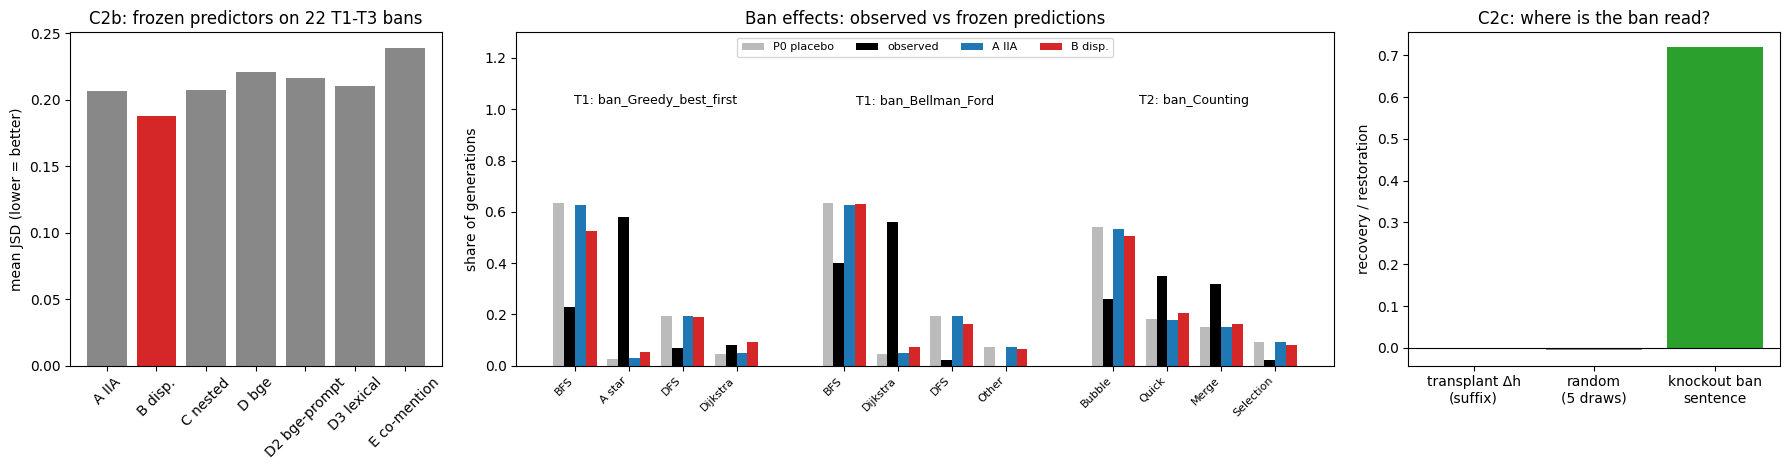

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw=dict(width_ratios=[1, 2.2, 1]))
# Left: C2b mean JSD per predictor
mj = c2b["mean_jsd"]
names = {"A": "A IIA", "B": "B disp.", "C": "C nested", "D": "D bge", "D2": "D2 bge-prompt", "D3": "D3 lexical", "E": "E co-mention"}
ks = list(mj)
axes[0].bar([names[k] for k in ks], [mj[k] for k in ks], color=["#888" if k != "B" else "#d62728" for k in ks])
axes[0].set_ylabel("mean JSD (lower = better)"); axes[0].set_title("C2b: frozen predictors on 22 T1-T3 bans")
axes[0].tick_params(axis="x", rotation=45)

# Middle: placebo vs observed vs predictions for showcase bans
sc = json.loads(data["results"]["predictor_scores_conf.json"])
fp = json.loads(data["results"]["frozen_predictions.json"])
show = [("T1", "ban_Greedy_best_first"), ("T1", "ban_Bellman_Ford"), ("T2", "ban_Counting")]
ax = axes[1]; xoff = 0; xt, xl = [], []
series = [("P0 placebo", "#bbb"), ("observed", "#000"), ("A IIA", "#1f77b4"), ("B disp.", "#d62728")]
for t, cond in show:
    cs = sc["conditions"][f"{t}/{cond}"]; K = fp["tasks"][t]["classes"]; pr = fp["tasks"][t]["conditions"][cond]["pred"]
    top = sorted(K, key=lambda k: -(cs["obs"][k] + cs["P0"][k]))[:4]  # 4 most relevant ideas
    for i, k in enumerate(top):
        j = K.index(k)
        vals = [cs["P0"][k], cs["obs"][k], pr["A"][j], pr["B"][j]]
        for s, ((lab, col), val) in enumerate(zip(series, vals)):
            ax.bar(xoff + i + (s - 1.5) * 0.2, val, 0.2, color=col, label=lab if (xoff == 0 and i == 0) else None)
        xt.append(xoff + i); xl.append(k.replace("_", " "))
    ax.text(xoff + 1.5, 1.02, f"{t}: {cond}", ha="center", fontsize=9)
    xoff += len(top) + 1
ax.set_xticks(xt); ax.set_xticklabels(xl, rotation=45, ha="right", fontsize=8); ax.set_ylim(0, 1.3)
ax.set_ylabel("share of generations"); ax.legend(fontsize=8, loc="upper center", ncol=4); ax.set_title("Ban effects: observed vs frozen predictions")

# Right: C2c transplant
s = c2c["summary"]
lab = ["transplant Δh\n(suffix)", "random\n(5 draws)", "knockout ban\nsentence"]
val = [s["mean_R_transplant"], s["mean_R_random"], s["mean_restoration_knockout_ban_sentence"]]
axes[2].bar(lab, val, color=["#d62728", "#888", "#2ca02c"]); axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_ylabel("recovery / restoration"); axes[2].set_title("C2c: where is the ban read?")
plt.tight_layout(); plt.show()

**Takeaways**
- Bans do not just remove an option and renormalise the rest (IIA). Banning a near-zero-rate idea such as greedy
  best-first moves A\* from about 3% to 58% and BFS from 63% to 23%. The prompt-suffix displacement Δh gets the
  *direction* of share changes right more often than IIA (0.83 vs 0.65).
- As a full distribution predictor, Δh improves on IIA by only 9.2%, short of the 20% target.
- Δh is not causal at the suffix: transplanting it recovers about 0 of the ban's effect. Knocking out attention to the
  ban sentence during decoding restores placebo behaviour, so the model re-reads the ban while it writes.